## 1. Import Necessary Libraries

In [68]:
import numpy as np
import matplotlib.pyplot as plt
import keras
import pandas as pd
from keras.models import Sequential
from keras.layers import Flatten,Dense,Dropout
from keras.utils import to_categorical

## 2. Data Collection

In [69]:
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()

## 3. Data Understanding

In [70]:
X_train.shape,y_train.shape

((50000, 32, 32, 3), (50000, 1))

In [71]:
X_test.shape,y_test.shape

((10000, 32, 32, 3), (10000, 1))

In [73]:
assert X_train.shape == (50000, 32, 32, 3)
assert X_test.shape == (10000, 32, 32, 3)
assert y_train.shape == (50000, 1)
assert y_test.shape == (10000, 1)

## 3.1 Define Class Lables

In [74]:
classes = ['Airplane',
           'Automobile',
           'Bird',
           'Cat',
           'Deer',
           'Dog',
           'Frog',
           'Horse',
           'Ship',
           'Truck']

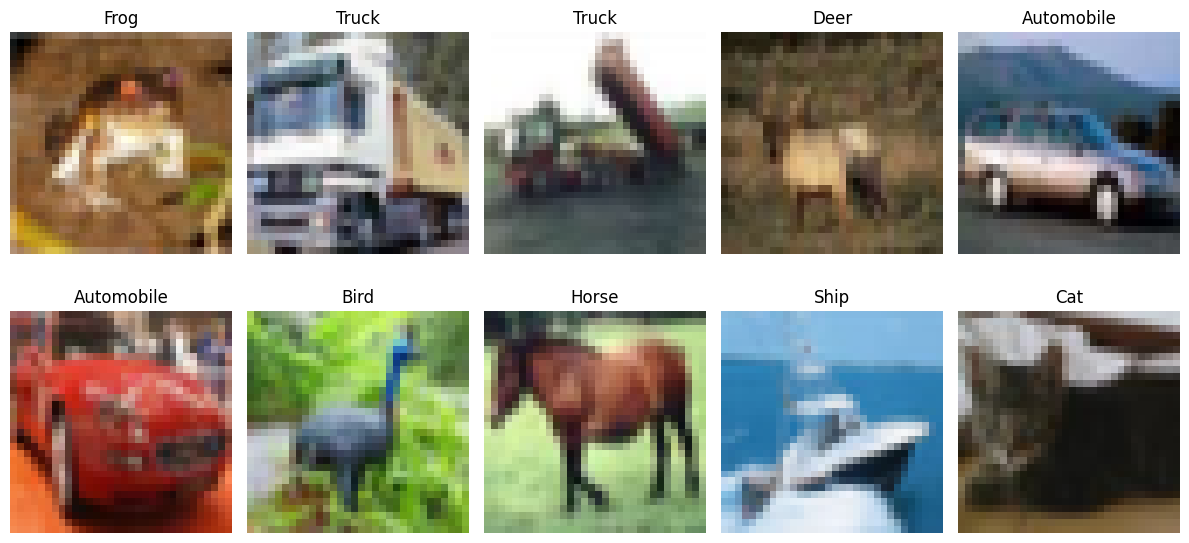

In [75]:
plt.figure(figsize = (12,6))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_train[i])
    plt.title(classes[int(y_train[i][0])])
    plt.axis("off")

plt.tight_layout()
plt.show()

## 4. Data Preparation

### Let's Normalize this for Faster Processing

In [76]:
X_train = X_train/255.0
X_test  = X_test/255.0

In [77]:
X_train.min(),X_train.max()

(np.float64(0.0), np.float64(1.0))

In [78]:
X_test.min(),X_test.max()

(np.float64(0.0), np.float64(1.0))

### One-Hot Encode Lables

In [79]:
y_train = to_categorical(y_train,10)
y_test = to_categorical(y_test,10)

print(y_train.shape)
print(y_test.shape)

(50000, 10)
(10000, 10)


## 5. Model Building

In [81]:
model = Sequential()

model.add(Flatten(input_shape=(32,32,3)))

model.add(Dense(512, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(256, activation='relu'))
model.add(Dropout(0.3))

model.add(Dense(128, activation='relu'))

model.add(Dense(10, activation='softmax'))


In [82]:
model.compile(optimizer = 'adam', loss = 'categorical_crossentropy', metrics = ['accuracy'])

In [83]:
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)                  │ (None, 3072)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_15 (Dense)                     │ (None, 512)                 │       1,573,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_6 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_16 (Dense)                     │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_7 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_17 (Dense)                     │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_18 (Dense)                     │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,738,890 (6.63 MB)

 Trainable params: 1,738,890 (6.63 MB)

 Non-trainable params: 0 (0.00 B)

In [84]:
history = model.fit(X_train, y_train, validation_split=0.2, epochs=20, batch_size=64)

Epoch 1/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 22ms/step - accuracy: 0.2367 - loss: 2.0485 - val_accuracy: 0.3319 - val_loss: 1.8983
Epoch 2/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.2842 - loss: 1.9301 - val_accuracy: 0.3322 - val_loss: 1.8557
Epoch 3/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.3013 - loss: 1.8959 - val_accuracy: 0.3425 - val_loss: 1.8263
Epoch 4/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.3078 - loss: 1.8670 - val_accuracy: 0.3357 - val_loss: 1.8515
Epoch 5/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 24ms/step - accuracy: 0.3176 - loss: 1.8509 - val_accuracy: 0.3406 - val_loss: 1.8254
Epoch 6/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 16s 25ms/step - accuracy: 0.3263 - loss: 1.8270 - val_accuracy: 0.3659 - val_loss: 1.7626
Epoch 7/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 19s 23ms/step - accuracy: 0.3357 - loss: 1.8123 - val_accuracy: 0.3811 - val_loss: 1.7624
Epoch 8/20
625/625 ━━━━━━━━━━━━━━━━━━━━ 15s 23ms/step - accuracy: 0.3386 - loss: 1.7960 - 

In [85]:
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


## Plot Accuracy

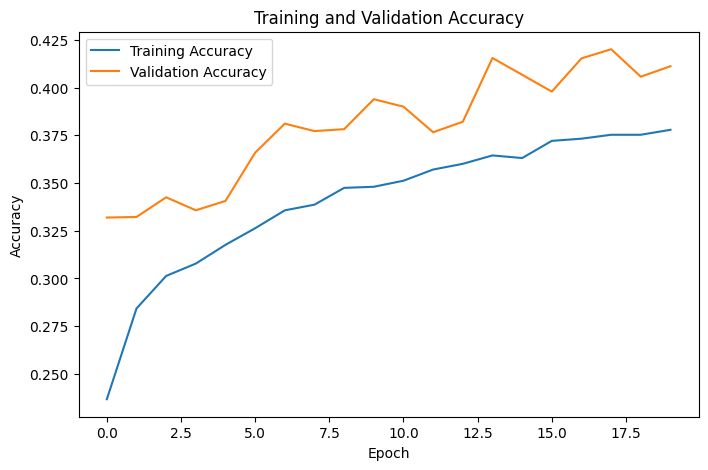

In [86]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()

plt.show()

## Plot Loss

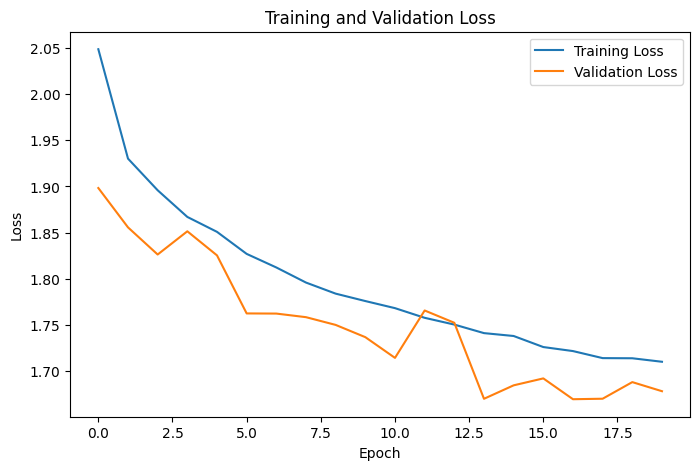

In [87]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()

plt.show()

## Predict Test Image

In [88]:
predictions = model.predict(X_test)

predicted_labels = np.argmax(predictions, axis=1)
actual_labels = np.argmax(y_test, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


## Display Predictions

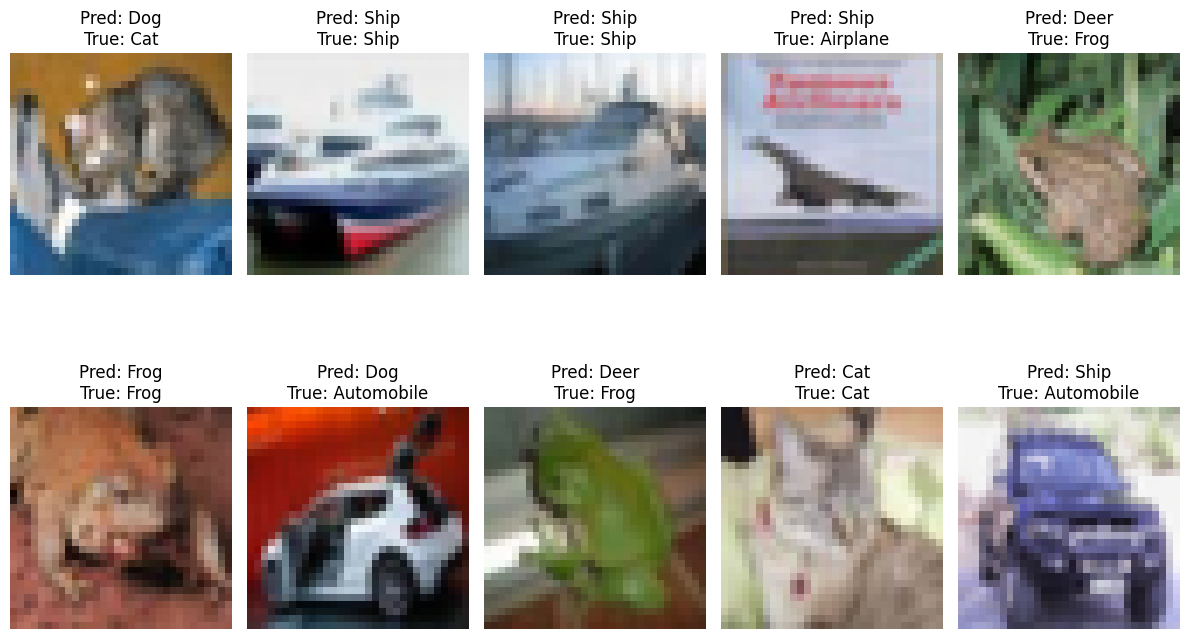

In [89]:
plt.figure(figsize=(12,8))

for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(X_test[i])
    plt.title(f"Pred: {classes[predicted_labels[i]]}\nTrue: {classes[actual_labels[i]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## Predict a Single Image

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step
Predicted Class : Truck
Actual Class    : Truck


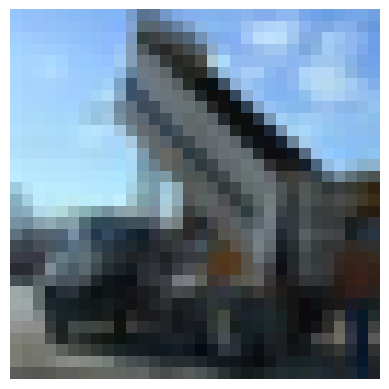

In [91]:
index = 50

sample = np.expand_dims(X_test[index],axis = 0)

prediction = model.predict(sample)

predicted_class = np.argmax(prediction)

print("Predicted Class :", classes[predicted_class])
print("Actual Class    :", classes[actual_labels[index]])

plt.imshow(X_test[index])
plt.axis("off")
plt.show()

## Save the Model

In [95]:
model.save("cifar10_mlp_model.keras")

print("Model Saved Successfully")

Model Saved Successfully
